In [12]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-

"""
create_total_eot20_sum.py
-------------------------
Sum *all* EOT20 ocean + load constituents (Hart-Davis et al. 2021)
and write a single NetCDF file with the total complex height.

Output:  EOT20_total_sum.nc   (dimensions: lat, lon)
         Variable: h_total (complex, units: m)
"""

import pathlib
import numpy as np
import xarray as xr


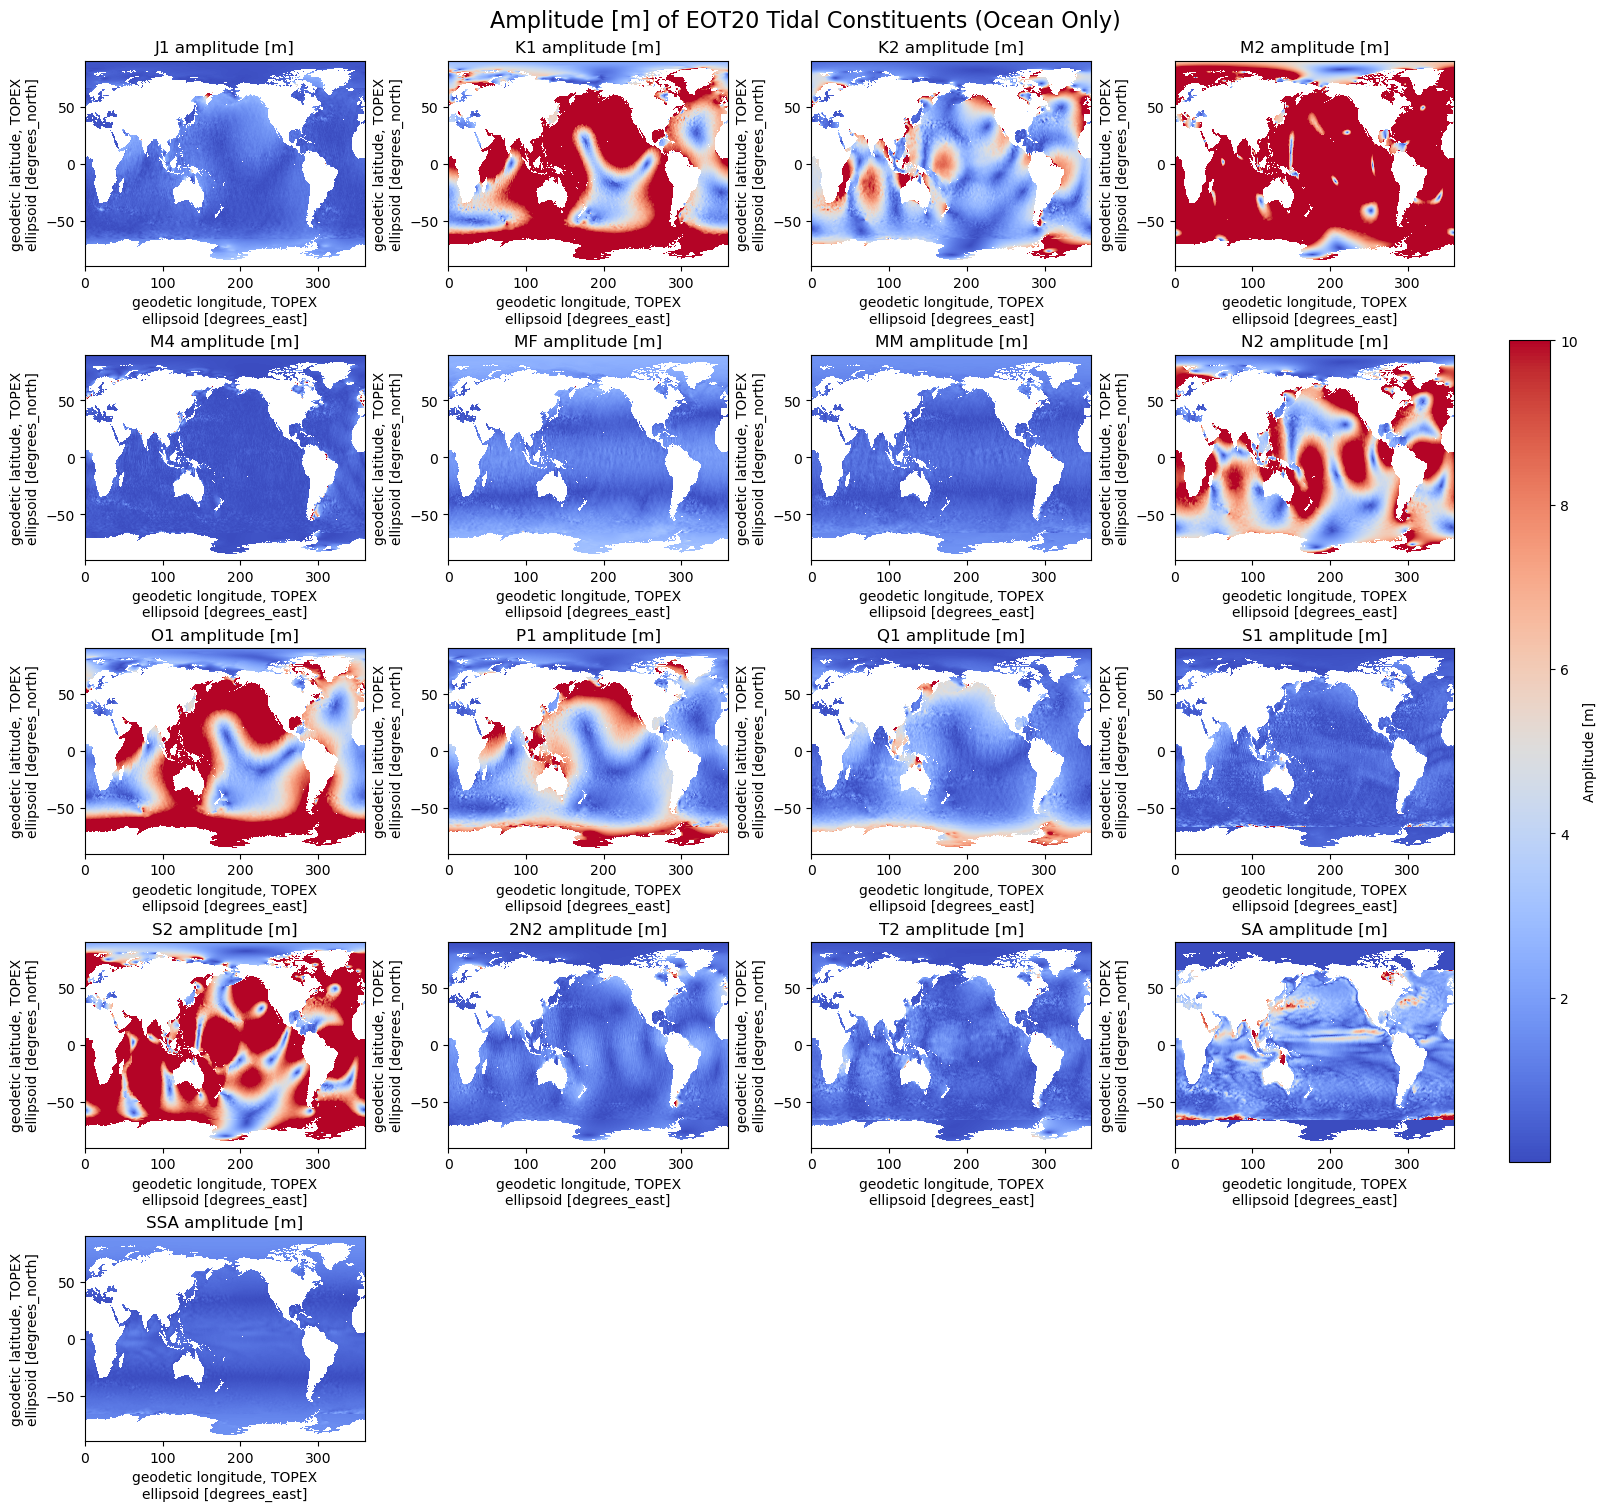

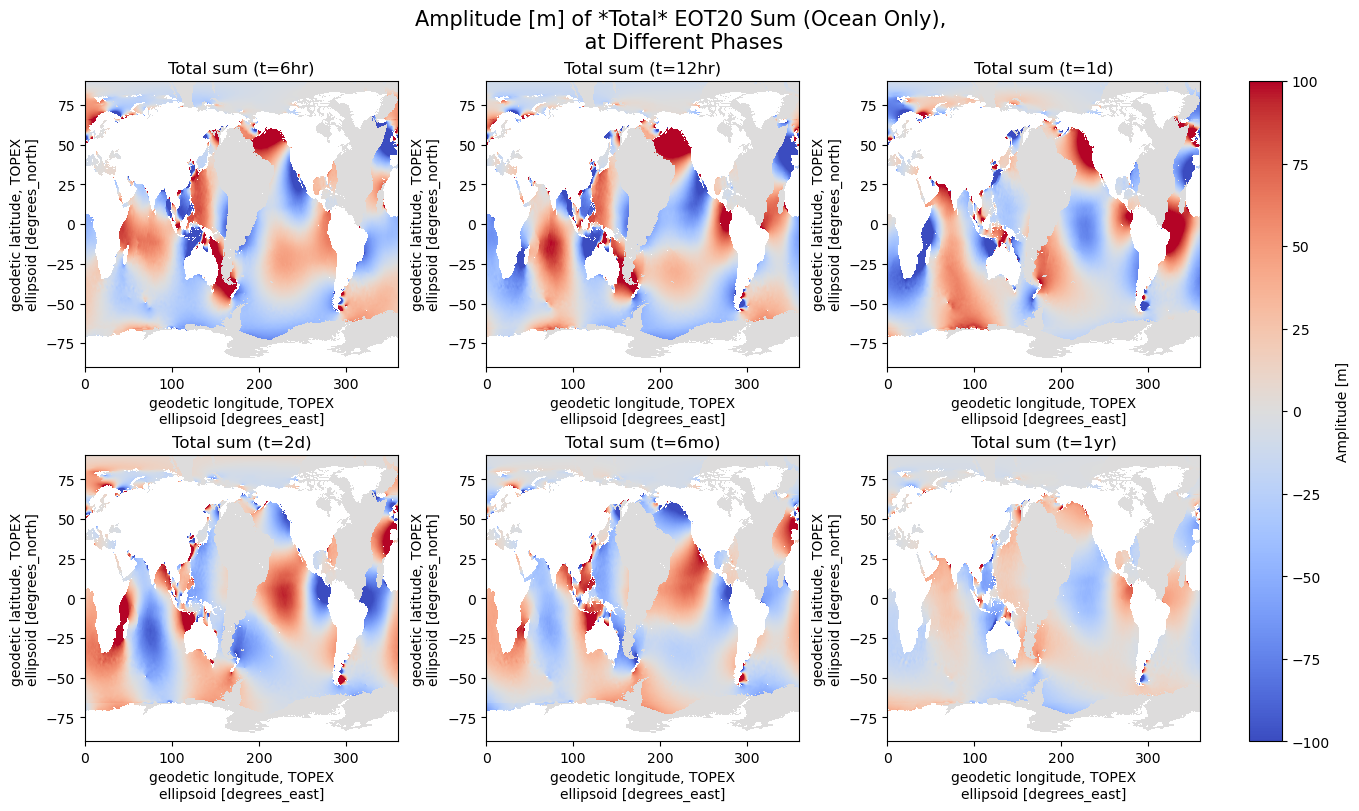

In [13]:
# --------------------------------------------------------------
# This cell computes the omega-weighted sum of EOT20 constituents at multiple time intervals,
# shows a multi-panel plot of constituent amplitudes, and creates a SEPARATE subplot
# for the total sum at each interval (not as just further panels in the main grid).
# No EOT20_sum.nc (or similar) file is written.
# Plotting of summed fields is done in-memory only.

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from pathlib import Path

# USE SUPPLIED LAND MASK FILE
land_file = Path().resolve().parents[1] / "data" / "raw" / "island_map.npy"
land_mask_raw = np.load(land_file)
land_mask_raw = np.rot90(np.rot90(np.fliplr(land_mask_raw)))
land_mask = land_mask_raw.copy()
land_mask[np.isnan(land_mask)] = 1  # 1 means land

DATA_DIR = pathlib.Path("/gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides")

TIDAL_CONSTITUENTS = [
    "J1", "K1", "K2", "M2", "M4", "MF", "MM", "N2", "O1", "P1",
    "Q1", "S1", "S2", "2N2", "T2", "SA", "SSA"
]
OMEGA_RAD = {
    "J1": 0.976506, "K1": 1.0027379, "K2": 2.0054758, "M2": 0.932273,
    "M4": 1.864546, "MF": 1.0980331, "MM": 0.053234, "N2": 0.895982,
    "O1": 0.929536, "P1": 0.997262, "Q1": 0.893244, "S1": 1.0,
    "S2": 2.0, "2N2": 0.897164, "T2": 2.0, "SA": 0.0, "SSA": 0.0
}

# Alignment for land mask and data
coords = None
shape_from_coords = None
for test_nc in DATA_DIR.glob("*_ocean_eot20.nc"):
    ds_test = xr.open_dataset(test_nc)
    if "amplitude" in ds_test.data_vars:
        data_amp = ds_test["amplitude"]
    else:
        data_amp = list(ds_test.data_vars.values())[0]
    coords = data_amp.coords
    shape_from_coords = data_amp.shape
    ds_test.close()
    break

if land_mask.shape != shape_from_coords:
    min0 = min(land_mask.shape[0], shape_from_coords[0])
    min1 = min(land_mask.shape[1], shape_from_coords[1])
    land_mask = land_mask[:min0, :min1]

land_mask_bin = (land_mask == 0).astype(np.uint8)  # 1: ocean, 0: land
nan_mask = np.where(land_mask_bin, 1, np.nan)  # 1: ocean, nan: land

# --- Compute total sum over constituents (omega-weighted) ---
nc_files = sorted(DATA_DIR.glob("*_ocean_eot20.nc"))

# Define the time intervals in seconds
time_intervals = {
    "6hr": 6 * 3600,
    "12hr": 12 * 3600,
    "1d": 24 * 3600,
    "2d": 2 * 24 * 3600,
    "6mo": 6 * 30.4375 * 24 * 3600,  # approx (6 months)
    "1yr": 365.25 * 24 * 3600         # 1 year
}

# Dict to hold: {interval_name: (sum_amplitude_array)}
h_total_by_interval = {k: None for k in time_intervals}

for f in nc_files:
    possible_name = f.stem.split('_')[0]
    if possible_name not in TIDAL_CONSTITUENTS:
        print(f"Skipping unknown or non-tidal constituent: {possible_name}")
        continue
    name = possible_name
    omega = OMEGA_RAD[name]
    omega_sec = omega / 3600.0  # radians per second

    ds = xr.open_dataset(f)
    amp = ds["amplitude"]
    phase = ds["phase"]
    # Convert phase to radians if provided in degrees
    phase_units = str(phase.attrs.get("units", "")).lower()
    if phase_units.startswith("deg"):
        phase_rad = np.deg2rad(phase)
    else:
        phase_rad = phase
    # Mask prior to summing, and fill nan with 0 for summation
    amp_ocean = amp.where(land_mask_bin).fillna(0)
    for interval_name, t_seconds in time_intervals.items():
        amp_at_t = amp_ocean * np.cos(omega_sec * t_seconds - phase_rad)
        if h_total_by_interval[interval_name] is None:
            h_total_by_interval[interval_name] = amp_at_t
        else:
            h_total_by_interval[interval_name] = h_total_by_interval[interval_name] + amp_at_t
    ds.close()

# --- Plot: All constituents in a grid, plus separate figure for summed total at all intervals ---

# Plot each constituent in a multi-panel grid
n_constituents = len(TIDAL_CONSTITUENTS)
ncols = 4
nrows = int(np.ceil(n_constituents / ncols))
fig_const, axes_const = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols * 4, nrows * 3), constrained_layout=True)
axes_const = axes_const.flatten()
img = None  # For colorbar

for i, constituent in enumerate(TIDAL_CONSTITUENTS):
    nc_file = next(DATA_DIR.glob(f"{constituent}_ocean_eot20.nc"), None)
    ax = axes_const[i]
    if nc_file is not None:
        try:
            ds = xr.open_dataset(nc_file)
            data_amp = ds["amplitude"]

            data_amp_m = data_amp  # amplitude is in meters
            if data_amp_m.shape != nan_mask.shape:
                min0 = min(data_amp_m.shape[0], nan_mask.shape[0])
                min1 = min(data_amp_m.shape[1], nan_mask.shape[1])
                data_plot_masked = data_amp_m[:min0, :min1] #* nan_mask[:min0, :min1]
            else:
                data_plot_masked = data_amp_m #* nan_mask
            data_plot = data_plot_masked
            # If data array has .plot, use for axes/labels
            if hasattr(data_plot, "plot"):
                img = data_plot.plot(ax=ax, add_colorbar=False, vmax=10, cmap = "coolwarm")
            else:
                img = ax.imshow(data_plot, origin='lower', aspect='auto', vmax=10, cmap = "coolwarm")
            ax.set_title(f"{constituent} amplitude [m]")
            ds.close()
        except Exception as e:
            ax.set_visible(False)
            print(f"Error reading/plotting {constituent}: {e}")
    else:
        ax.set_visible(False)
        print(f"No file found for constituent: {constituent}")

# Hide unused axes in constituent grid
for j in range(n_constituents, len(axes_const)):
    axes_const[j].set_visible(False)

if img is not None:
    fig_const.colorbar(img, ax=axes_const[:n_constituents], orientation="vertical", fraction=0.03, pad=0.04, label='Amplitude [m]')

plt.suptitle("Amplitude [m] of EOT20 Tidal Constituents (Ocean Only)", fontsize=16)
plt.show()


# --- NEW: Separate subplot figure for summed-up tidal constituents at different intervals ---

intervals_to_plot = list(time_intervals.keys())
n_sums = len(intervals_to_plot)
ncols_sums = 3
nrows_sums = int(np.ceil(n_sums / ncols_sums))
fig_sum, axes_sum = plt.subplots(nrows=nrows_sums, ncols=ncols_sums, figsize=(ncols_sums * 4.5, nrows_sums * 4), constrained_layout=True)
axes_sum = axes_sum.flatten()
img_sum = None

for idx, interval in enumerate(intervals_to_plot):
    ax_total = axes_sum[idx]
    h_tot = h_total_by_interval[interval]
    if h_tot is not None:
        # Mask using nan_mask
        if hasattr(h_tot, "shape") and h_tot.shape != nan_mask.shape:
            min0 = min(h_tot.shape[0], nan_mask.shape[0])
            min1 = min(h_tot.shape[1], nan_mask.shape[1])
            h_tot_masked = h_tot[:min0, :min1] #* nan_mask[:min0, :min1]
        else:
            h_tot_masked = h_tot #* nan_mask
        h_tot_plot = h_tot_masked
        if hasattr(h_tot_plot, "plot"):
            img_sum = h_tot_plot.plot(ax=ax_total, add_colorbar=False, cmap="coolwarm", vmin=-100, vmax=100)
        else:
            img_sum = ax_total.imshow(h_tot_plot, origin='lower', aspect='auto', cmap="coolwarm", vmin=-100, vmax=100)
        ax_total.set_title(f"Total sum (t={interval})")
    else:
        ax_total.set_visible(False)
        print(f"Missing total array for {interval} interval.")

# Hide unused axes in sum grid
for j in range(n_sums, len(axes_sum)):
    axes_sum[j].set_visible(False)

if img_sum is not None:
    fig_sum.colorbar(img_sum, ax=axes_sum[:n_sums], orientation="vertical", fraction=0.03, pad=0.04, label='Amplitude [m]')

plt.suptitle("Amplitude [m] of *Total* EOT20 Sum (Ocean Only),\n at Different Phases", fontsize=15)
plt.show()


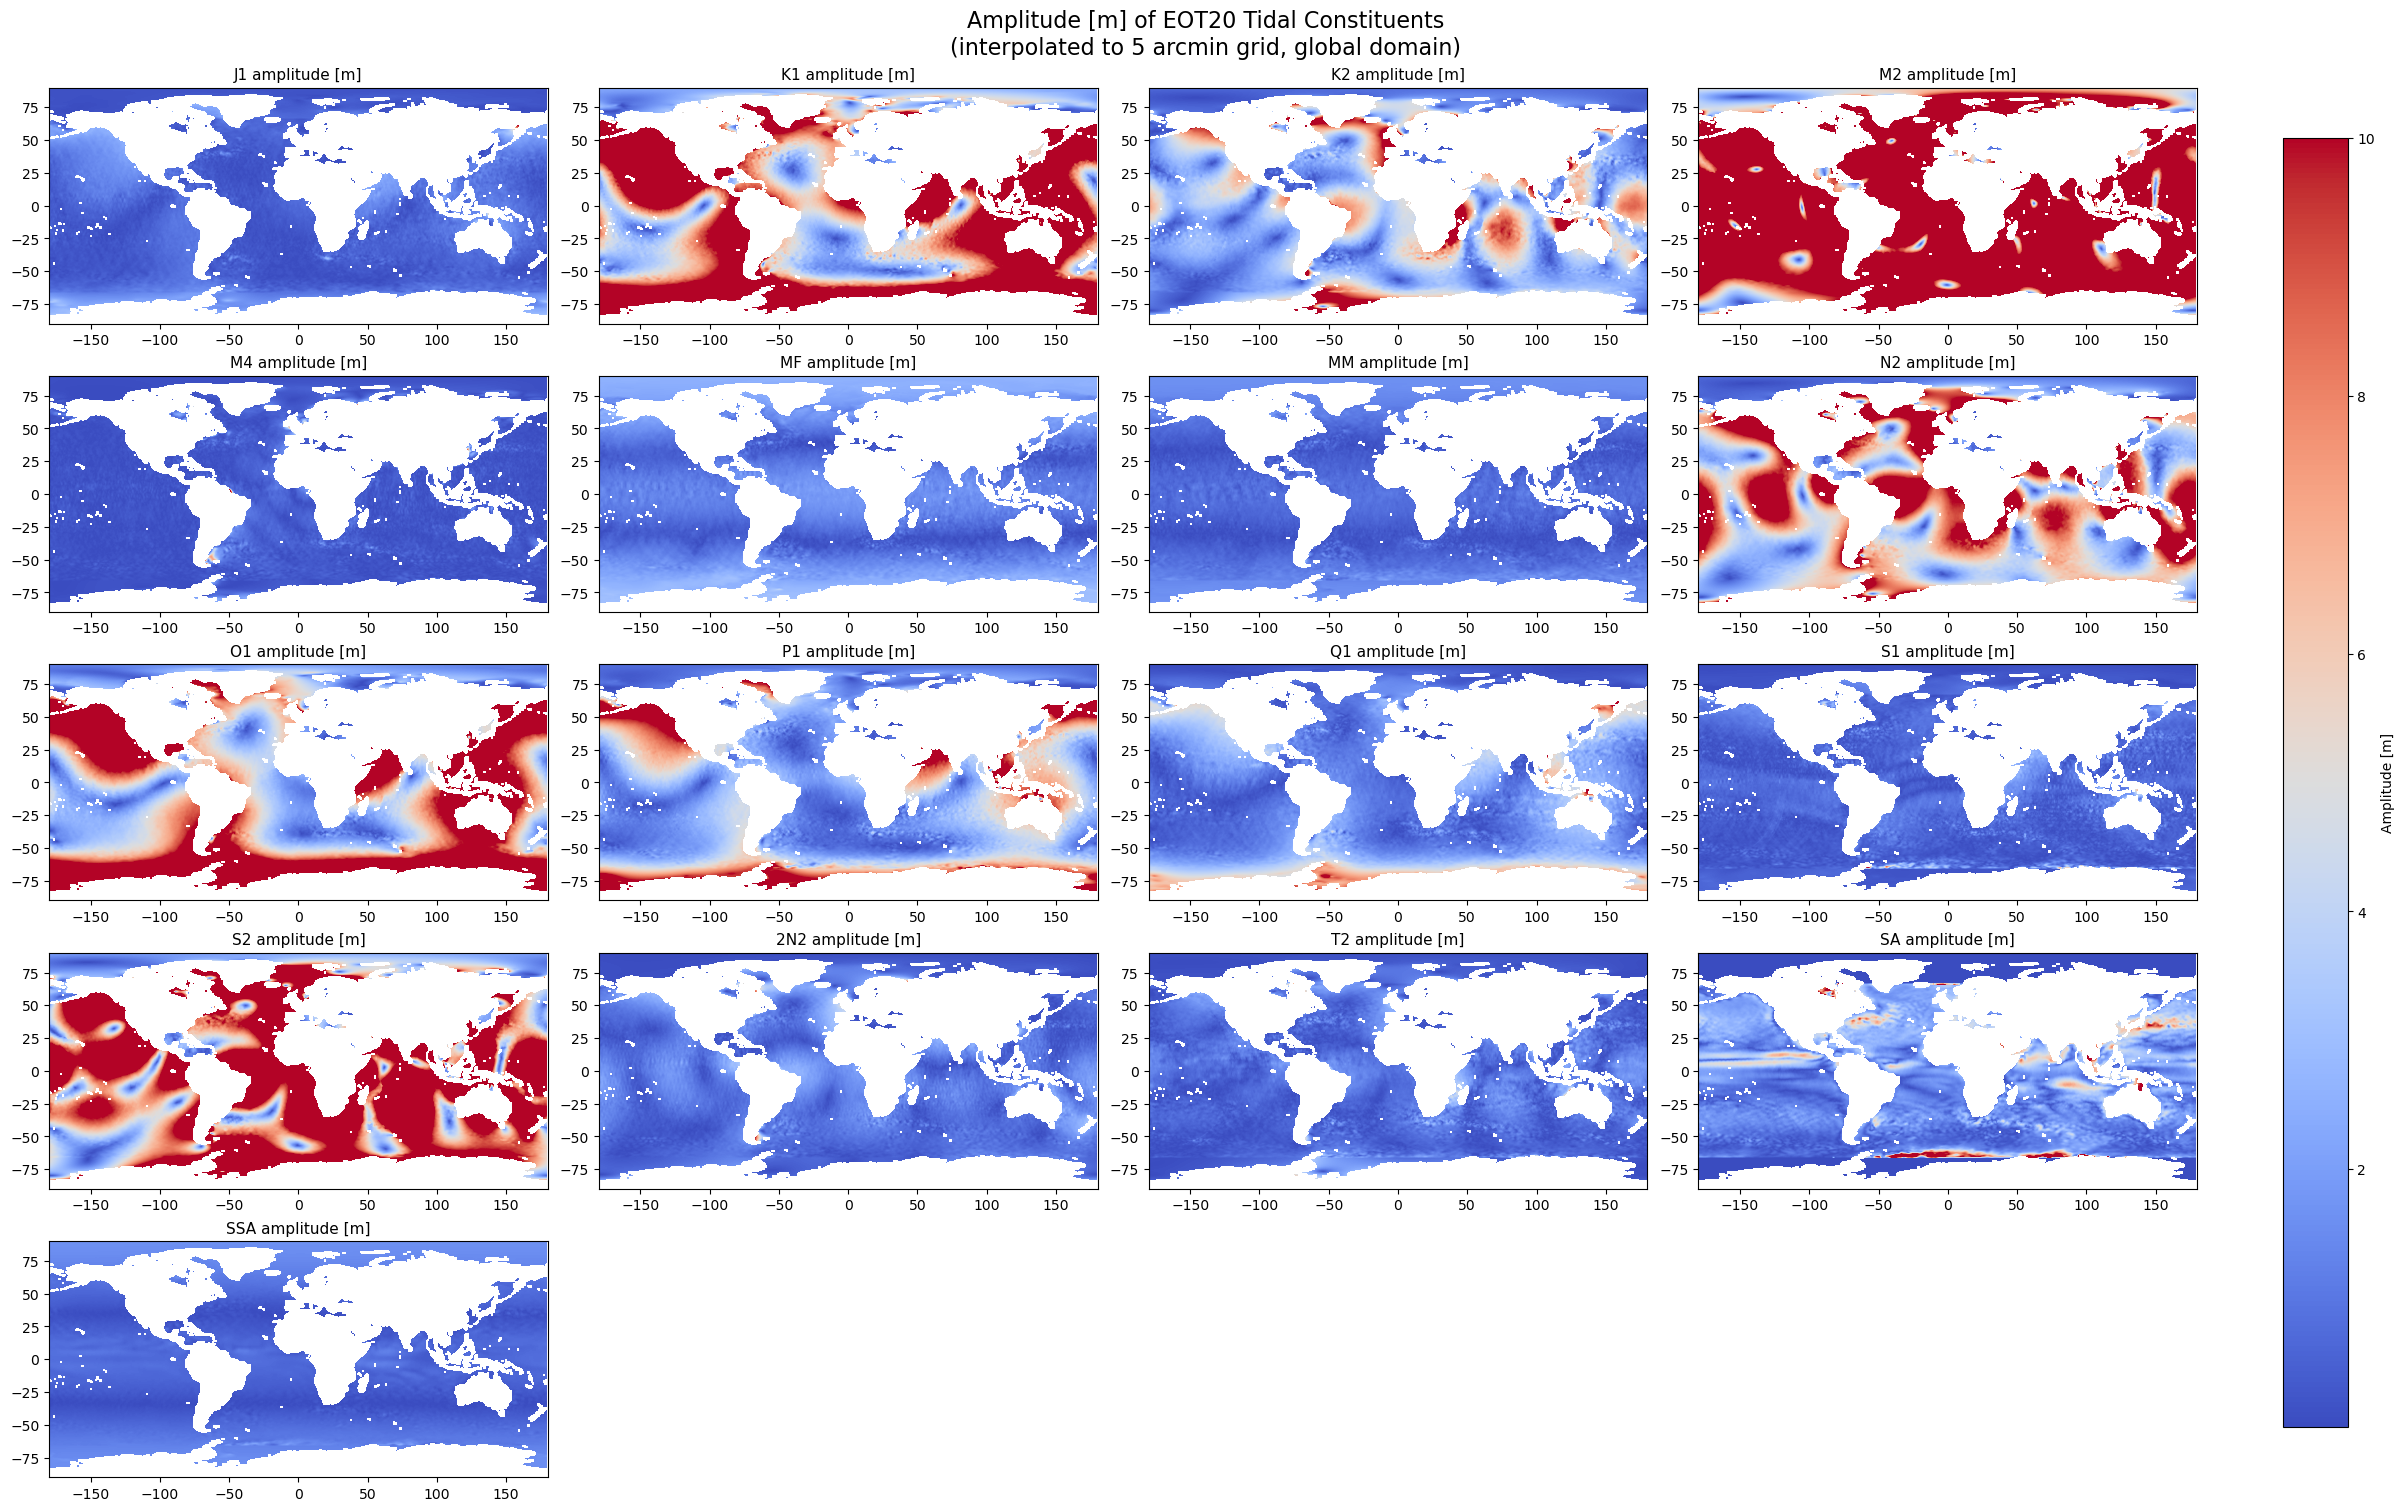

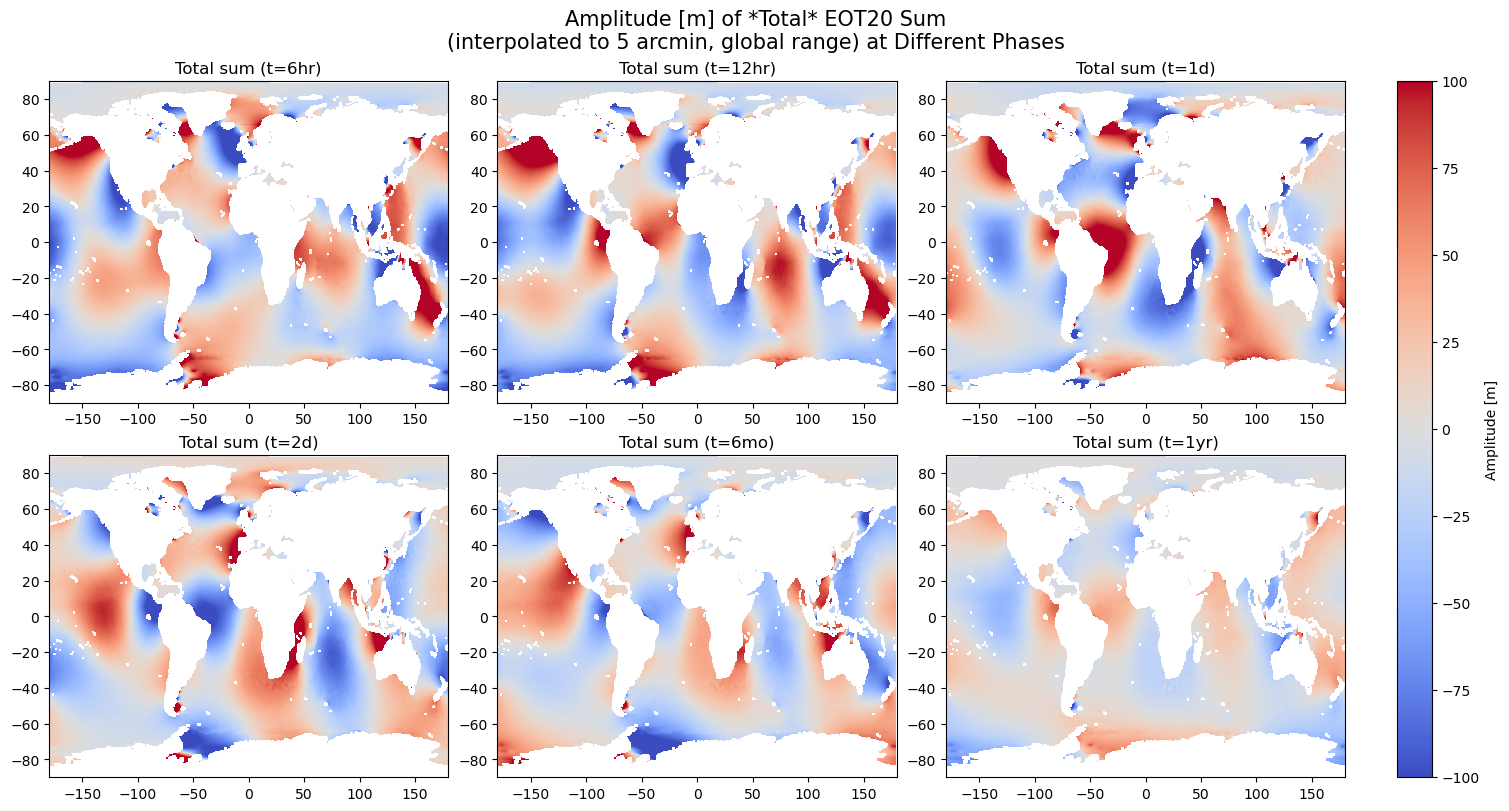

In [14]:
# --------------------------------------------------------------
# This cell computes the omega-weighted sum of EOT20 constituents at multiple time intervals,
# shows a multi-panel plot of constituent amplitudes, and creates a SEPARATE subplot
# for the total sum at each interval (not as just further panels in the main grid).
# No EOT20_sum.nc (or similar) file is written.
# Plotting of summed fields is done in-memory only.
# Modified:
#   1. Removes all nan/ocean/land masking.
#   2. Converts data to 2160x4320 grid (5 arcmin) for plotting, by interpolation.
#   3. Sets x/y extent to global domain (-180,180), (-90,90).
#   4. Fixes "InvalidIndexError: Reindexing only valid with uniquely valued Index objects"
#      by enforcing unique and sorted lon/lat before interpolation.
#   5. Fixes swap of lat/lon axes in imshow: use correct orientation & extent.

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import pathlib
from pathlib import Path

DATA_DIR = pathlib.Path("/gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides")

TIDAL_CONSTITUENTS = [
    "J1", "K1", "K2", "M2", "M4", "MF", "MM", "N2", "O1", "P1",
    "Q1", "S1", "S2", "2N2", "T2", "SA", "SSA"
]
OMEGA_RAD = {
    "J1": 0.976506, "K1": 1.0027379, "K2": 2.0054758, "M2": 0.932273,
    "M4": 1.864546, "MF": 1.0980331, "MM": 0.053234, "N2": 0.895982,
    "O1": 0.929536, "P1": 0.997262, "Q1": 0.893244, "S1": 1.0,
    "S2": 2.0, "2N2": 0.897164, "T2": 2.0, "SA": 0.0, "SSA": 0.0
}

# Utility function: remove duplicate/unsorted coordinates for valid .interp (xarray)
def ensure_unique_sorted_coords(da, lat_dim='lat', lon_dim='lon'):
    # Identify axis names if not standard
    dims = da.dims
    if lat_dim not in dims:
        for d in dims:
            if 'lat' in d.lower() or d.lower().startswith('y'):
                lat_dim = d
    if lon_dim not in dims:
        for d in dims:
            if 'lon' in d.lower() or d.lower().startswith('x'):
                lon_dim = d

    arr = da.copy(deep=False)
    # 1. Remove duplicates for both lat and lon coordinates
    for dim in [lat_dim, lon_dim]:
        coords = arr[dim].values
        _, idx = np.unique(coords, return_index=True)
        idx = np.sort(idx)
        arr = arr.isel({dim: idx})
    # 2. Sort along both axes
    arr = arr.sortby([lat_dim, lon_dim])
    return arr

# Set up 5 arc-min grid: 2160x4320, longitude -180 to 180, latitude -90 to 90
nlat, nlon = 2160, 4320
lats_5arcmin = np.linspace(-90, 90, nlat)
lons_5arcmin = np.linspace(-180, 180, nlon)

def interp_to_5arcmin_grid(array, lat_dim='lat', lon_dim='lon'):
    """Interpolates 2D xarray.DataArray or np.ndarray to 2160x4320 grid (preparing valid coords)."""
    if isinstance(array, xr.DataArray):
        dims = array.dims
        possible_lat = [d for d in dims if 'lat' in d.lower() or d.lower().startswith('y')]
        possible_lon = [d for d in dims if 'lon' in d.lower() or d.lower().startswith('x')]
        if possible_lat: lat_dim = possible_lat[0]
        if possible_lon: lon_dim = possible_lon[0]
        # Fix: remove duplicate coords & sort for both axes
        array = ensure_unique_sorted_coords(array, lat_dim=lat_dim, lon_dim=lon_dim)
        # If lons are 0-360, shift to -180:180 if needed
        lons = array[lon_dim].values
        if np.nanmax(lons) > 180:
            lons = ((lons + 180) % 360) - 180
            # sort after shifting to avoid duplicate 180/–180
            array = array.assign_coords({lon_dim: lons})
            array = ensure_unique_sorted_coords(array, lat_dim=lat_dim, lon_dim=lon_dim)
        arr_interp = array.interp(
            {lat_dim: lats_5arcmin, lon_dim: lons_5arcmin},
            method="linear",
            kwargs={"fill_value": np.nan}
        )
        return arr_interp
    else:
        # assume raw numpy shape: match original file's
        arr0 = array
        if arr0.shape != (nlat, nlon):
            from scipy.ndimage import zoom
            arr_interp = zoom(arr0, (nlat/arr0.shape[0], nlon/arr0.shape[1]), order=1)
            return arr_interp
        else:
            return arr0

# --- Compute total sum over constituents (omega-weighted) ---
nc_files = sorted(DATA_DIR.glob("*_ocean_eot20.nc"))

# Define the time intervals in seconds
time_intervals = {
    "6hr": 6 * 3600,
    "12hr": 12 * 3600,
    "1d": 24 * 3600,
    "2d": 2 * 24 * 3600,
    "6mo": 6 * 30.4375 * 24 * 3600,  # approx (6 months)
    "1yr": 365.25 * 24 * 3600         # 1 year
}

# Dict to hold: {interval_name: (sum_amplitude_array)}
h_total_by_interval = {k: None for k in time_intervals}

for f in nc_files:
    possible_name = f.stem.split('_')[0]
    if possible_name not in TIDAL_CONSTITUENTS:
        print(f"Skipping unknown or non-tidal constituent: {possible_name}")
        continue
    name = possible_name
    omega = OMEGA_RAD[name]
    omega_sec = omega / 3600.0  # radians per second

    ds = xr.open_dataset(f)
    amp = ds["amplitude"]
    phase = ds["phase"]
    # Convert phase to radians if provided in degrees
    phase_units = str(phase.attrs.get("units", "")).lower()
    if phase_units.startswith("deg"):
        phase_rad = np.deg2rad(phase)
    else:
        phase_rad = phase
    amp_ocean = amp # no masking
    for interval_name, t_seconds in time_intervals.items():
        amp_at_t = amp_ocean * np.cos(omega_sec * t_seconds - phase_rad)
        if h_total_by_interval[interval_name] is None:
            h_total_by_interval[interval_name] = amp_at_t
        else:
            h_total_by_interval[interval_name] = h_total_by_interval[interval_name] + amp_at_t
    ds.close()

# --- Plot: All constituents in a multi-panel grid (lat-lon orientation fixed) ---

n_constituents = len(TIDAL_CONSTITUENTS)
ncols = 4
nrows = int(np.ceil(n_constituents / ncols))
fig_const, axes_const = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols * 6, nrows * 3), constrained_layout=True)
axes_const = axes_const.flatten()
img = None  # For colorbar

for i, constituent in enumerate(TIDAL_CONSTITUENTS):
    nc_file = next(DATA_DIR.glob(f"{constituent}_ocean_eot20.nc"), None)
    ax = axes_const[i]
    if nc_file is not None:
        try:
            ds = xr.open_dataset(nc_file)
            data_amp = ds["amplitude"]
            data_amp = ensure_unique_sorted_coords(data_amp)  # <--- fix for .interp
            data_plot = interp_to_5arcmin_grid(data_amp)

            # Always plot as [nlat, nlon] (y,x) in imshow,
            # so use extent = [lonmin, lonmax, latmin, latmax]
            if isinstance(data_plot, xr.DataArray):
                arr_plot = data_plot.values
            else:
                arr_plot = data_plot

            # No need to transpose:  arr_plot.shape = (nlat, nlon)
            # Extent: [x0, x1, y0, y1]:  (lons, lats)
            img = ax.imshow(
                arr_plot,
                extent=[-180, 180, -90, 90],  # x0, x1, y0, y1  (lon, lat)
                origin='lower',
                aspect='auto',
                vmax=10,
                cmap="coolwarm"
            )
            ax.set_title(f"{constituent} amplitude [m]", fontsize=11)
            ax.set_xlim(-180, 180)
            ax.set_ylim(-90, 90)
            ds.close()
        except Exception as e:
            ax.set_visible(False)
            print(f"Error reading/plotting {constituent}: {e}")
    else:
        ax.set_visible(False)
        print(f"No file found for constituent: {constituent}")

# Hide unused axes in constituent grid
for j in range(n_constituents, len(axes_const)):
    axes_const[j].set_visible(False)

if img is not None:
    fig_const.colorbar(img, ax=axes_const[:n_constituents], orientation="vertical", fraction=0.03, pad=0.04, label='Amplitude [m]')

plt.suptitle("Amplitude [m] of EOT20 Tidal Constituents\n(interpolated to 5 arcmin grid, global domain)", fontsize=16)
plt.show()

# --- NEW: Separate subplot figure for summed-up tidal constituents at different intervals (lat/lon orientation fixed) ---

intervals_to_plot = list(time_intervals.keys())
n_sums = len(intervals_to_plot)
ncols_sums = 3
nrows_sums = int(np.ceil(n_sums / ncols_sums))
fig_sum, axes_sum = plt.subplots(nrows=nrows_sums, ncols=ncols_sums, figsize=(ncols_sums * 5, nrows_sums * 4), constrained_layout=True)
axes_sum = axes_sum.flatten()
img_sum = None

for idx, interval in enumerate(intervals_to_plot):
    ax_total = axes_sum[idx]
    h_tot = h_total_by_interval[interval]
    if h_tot is not None:
        # Fix: ensure unique/sorted coords before interpolation
        if isinstance(h_tot, xr.DataArray):
            h_tot = ensure_unique_sorted_coords(h_tot)
        h_tot_plot = interp_to_5arcmin_grid(h_tot)
        if isinstance(h_tot_plot, xr.DataArray):
            arr_plot = h_tot_plot.values
        else:
            arr_plot = h_tot_plot
        # No transpose; arr_plot.shape = (nlat, nlon) = (lat, lon)
        img_sum = ax_total.imshow(
            arr_plot,
            extent=[-180, 180, -90, 90],    # x0, x1, y0, y1  (lon, lat)
            origin='lower',
            aspect='auto',
            cmap="coolwarm",
            vmin=-100,
            vmax=100
        )
        ax_total.set_title(f"Total sum (t={interval})", fontsize=12)
        ax_total.set_xlim(-180, 180)
        ax_total.set_ylim(-90, 90)
    else:
        ax_total.set_visible(False)
        print(f"Missing total array for {interval} interval.")

# Hide unused axes in sum grid
for j in range(n_sums, len(axes_sum)):
    axes_sum[j].set_visible(False)

if img_sum is not None:
    fig_sum.colorbar(img_sum, ax=axes_sum[:n_sums], orientation="vertical", fraction=0.03, pad=0.04, label='Amplitude [m]')

plt.suptitle("Amplitude [m] of *Total* EOT20 Sum\n(interpolated to 5 arcmin, global range) at Different Phases", fontsize=15)
plt.show()


In [15]:
# --------------------------------------------------------------
# This cell computes key tidal statistics maps for EOT20, corresponding to sediment transport proxies:
# 1. Maximum Current Speed (Umax): Highest amplitude summed over constituents (over all phase, i.e. sum of amplitudes).
# 2. RMS Current Speed (Urms): sqrt(<U^2>), i.e. RMS amplitude, as energy proxy.
# 3. Tidal Power Proxy (U3, U4): Mean of U(t)^3 or U(t)^4 in time, proportional to non-linear transport.
# 4. Tidal Range/Type Ratio: (K1 + O1) / (M2 + S2), diurnal/semi-diurnal diagnostic.
# Each field is interpolated to a 5 arcmin grid (2160x4320), with no land/ocean masking.

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import pathlib

DATA_DIR = pathlib.Path("/gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides")

TIDAL_CONSTITUENTS = [
    "J1", "K1", "K2", "M2", "M4", "MF", "MM", "N2", "O1", "P1",
    "Q1", "S1", "S2", "2N2", "T2", "SA", "SSA"
]
OMEGA_RAD = {
    "J1": 0.976506, "K1": 1.0027379, "K2": 2.0054758, "M2": 0.932273,
    "M4": 1.864546, "MF": 1.0980331, "MM": 0.053234, "N2": 0.895982,
    "O1": 0.929536, "P1": 0.997262, "Q1": 0.893244, "S1": 1.0,
    "S2": 2.0, "2N2": 0.897164, "T2": 2.0, "SA": 0.0, "SSA": 0.0
}

# Utility for ensuring unique/sorted axes for interp
def ensure_unique_sorted_coords(da, lat_dim='lat', lon_dim='lon'):
    dims = da.dims
    if lat_dim not in dims:
        for d in dims:
            if 'lat' in d.lower() or d.lower().startswith('y'):
                lat_dim = d
    if lon_dim not in dims:
        for d in dims:
            if 'lon' in d.lower() or d.lower().startswith('x'):
                lon_dim = d
    arr = da.copy(deep=False)
    for dim in [lat_dim, lon_dim]:
        coords = arr[dim].values
        _, idx = np.unique(coords, return_index=True)
        idx = np.sort(idx)
        arr = arr.isel({dim: idx})
    arr = arr.sortby([lat_dim, lon_dim])
    return arr

nlat, nlon = 2160, 4320
lats_5arcmin = np.linspace(-90, 90, nlat)
lons_5arcmin = np.linspace(-180, 180, nlon)

def interp_to_5arcmin_grid(array, lat_dim='lat', lon_dim='lon'):
    import scipy.ndimage
    if isinstance(array, xr.DataArray):
        dims = array.dims
        possible_lat = [d for d in dims if 'lat' in d.lower() or d.lower().startswith('y')]
        possible_lon = [d for d in dims if 'lon' in d.lower() or d.lower().startswith('x')]
        if possible_lat: lat_dim = possible_lat[0]
        if possible_lon: lon_dim = possible_lon[0]
        array = ensure_unique_sorted_coords(array, lat_dim=lat_dim, lon_dim=lon_dim)
        lons = array[lon_dim].values
        if np.nanmax(lons) > 180:
            lons = ((lons + 180) % 360) - 180
            array = array.assign_coords({lon_dim: lons})
            array = ensure_unique_sorted_coords(array, lat_dim=lat_dim, lon_dim=lon_dim)
        arr_interp = array.interp(
            {lat_dim: lats_5arcmin, lon_dim: lons_5arcmin},
            method="linear",
            kwargs={"fill_value": np.nan}
        )
        return arr_interp
    else:
        arr0 = array
        if arr0.shape != (nlat, nlon):
            from scipy.ndimage import zoom
            arr_interp = zoom(arr0, (nlat/arr0.shape[0], nlon/arr0.shape[1]), order=1)
            return arr_interp
        else:
            return arr0

# Load amplitudes and phases for all constituents, and interpolate to output grid
const_amps = {}
const_phases = {}

for tc in TIDAL_CONSTITUENTS:
    f = next(DATA_DIR.glob(f"{tc}_ocean_eot20.nc"), None)
    if f is None:
        print(f"Missing {tc}")
        continue
    ds = xr.open_dataset(f)
    amp = ds["amplitude"]
    phase = ds["phase"]
    phase = np.deg2rad(phase) if str(phase.attrs.get("units", "")).lower().startswith("deg") else phase
    amp = ensure_unique_sorted_coords(amp)
    phase = ensure_unique_sorted_coords(phase)
    amp_interp = interp_to_5arcmin_grid(amp)
    phase_interp = interp_to_5arcmin_grid(phase)
    const_amps[tc] = amp_interp.values if isinstance(amp_interp, xr.DataArray) else amp_interp
    const_phases[tc] = phase_interp.values if isinstance(phase_interp, xr.DataArray) else phase_interp
    ds.close()

# -- 1. Umax: Maximum current speed that occurs at any phase --
# This is sum(abs(amplitude)) *only valid* for 1 constituent, but for multi-harmonic:
# The true Umax is found by evaluating the sum-of-waves at all possible phases in each grid cell.
# We estimate Umax over N uniform samples in phase over ~18.6 years (the full nodal cycle).

# Synthesize time axis spanning 18.61 years (~longest astronomical tidal cycle, in seconds):
nodal_cycle_years = 18.61
nodal_cycle_sec = int(nodal_cycle_years * 365.25 * 24 * 3600)
dt_hours = 1
t_syn = np.arange(0, nodal_cycle_sec, dt_hours * 3600)  # 1 hour sampling

amps_stack = np.stack([const_amps[k] for k in TIDAL_CONSTITUENTS if k in const_amps])   # [nconst, nlat, nlon]
phases_stack = np.stack([const_phases[k] for k in TIDAL_CONSTITUENTS if k in const_phases])
omegas = np.array([OMEGA_RAD[k] / 3600.0 for k in TIDAL_CONSTITUENTS if k in const_amps])  # radians/sec

# This block simulates the full combined signal over a long cycle for each grid cell,
# to get Umax, Urms, <U^3>, <U^4> with maximum accuracy.
nconst, nlat, nlon = amps_stack.shape
n_t = len(t_syn)

# We'll compute in batches due to memory (or stride the times):
# Pick ~1000 time points evenly distributed through the full cycle (to get all spring-neap/nodal resonances).
nt_samp = 1000
t_sample = np.linspace(0, nodal_cycle_sec, nt_samp)  # in seconds

U_cube = np.zeros((nt_samp, nlat, nlon), dtype=np.float32)

for i, ti in enumerate(t_sample):
    # U(t) = sum_j A_j * cos(omega_j * t + phi_j) for each j
    phases = omegas[:, None, None] * ti - phases_stack
    U = np.sum(amps_stack * np.cos(phases), axis=0)
    U_cube[i, :, :] = U

# 1. Umax: peak speed over the nodal cycle (for each pixel)
Umax = np.nanmax(np.abs(U_cube), axis=0)  # [nlat, nlon]

# 2. Urms: RMS current speed (sqrt(mean(U^2)))
Urms = np.sqrt(np.nanmean(U_cube**2, axis=0))  # [nlat, nlon]

# 3. Power proxies U3/U4:
U3 = np.nanmean(np.abs(U_cube)**3, axis=0)
U4 = np.nanmean(np.abs(U_cube)**4, axis=0)

# -- 4. Tidal type/range ratio: (K1 + O1) / (M2 + S2) --
# Use amplitude fields directly (not combined over time)
a_K1 = const_amps["K1"] if "K1" in const_amps else np.nan
a_O1 = const_amps["O1"] if "O1" in const_amps else np.nan
a_M2 = const_amps["M2"] if "M2" in const_amps else np.nan
a_S2 = const_amps["S2"] if "S2" in const_amps else np.nan
ratio_diurnal_semidiurnal = (a_K1 + a_O1) / (a_M2 + a_S2)


/tmp/ipykernel_2768351/2449458795.py:135: RuntimeWarning: All-NaN slice encountered
  Umax = np.nanmax(np.abs(U_cube), axis=0)  # [nlat, nlon]
/tmp/ipykernel_2768351/2449458795.py:138: RuntimeWarning: Mean of empty slice
  Urms = np.sqrt(np.nanmean(U_cube**2, axis=0))  # [nlat, nlon]
/tmp/ipykernel_2768351/2449458795.py:141: RuntimeWarning: Mean of empty slice
  U3 = np.nanmean(np.abs(U_cube)**3, axis=0)
/tmp/ipykernel_2768351/2449458795.py:142: RuntimeWarning: Mean of empty slice
  U4 = np.nanmean(np.abs(U_cube)**4, axis=0)


Saving umax to /gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_umax_5arcmin.nc
Saving urms to /gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_urms_5arcmin.nc
Saving u3 to /gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_u3_5arcmin.nc
Saving u4 to /gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_u4_5arcmin.nc
Saving tidal_ratio to /gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_tidal_ratio_5arcmin.nc


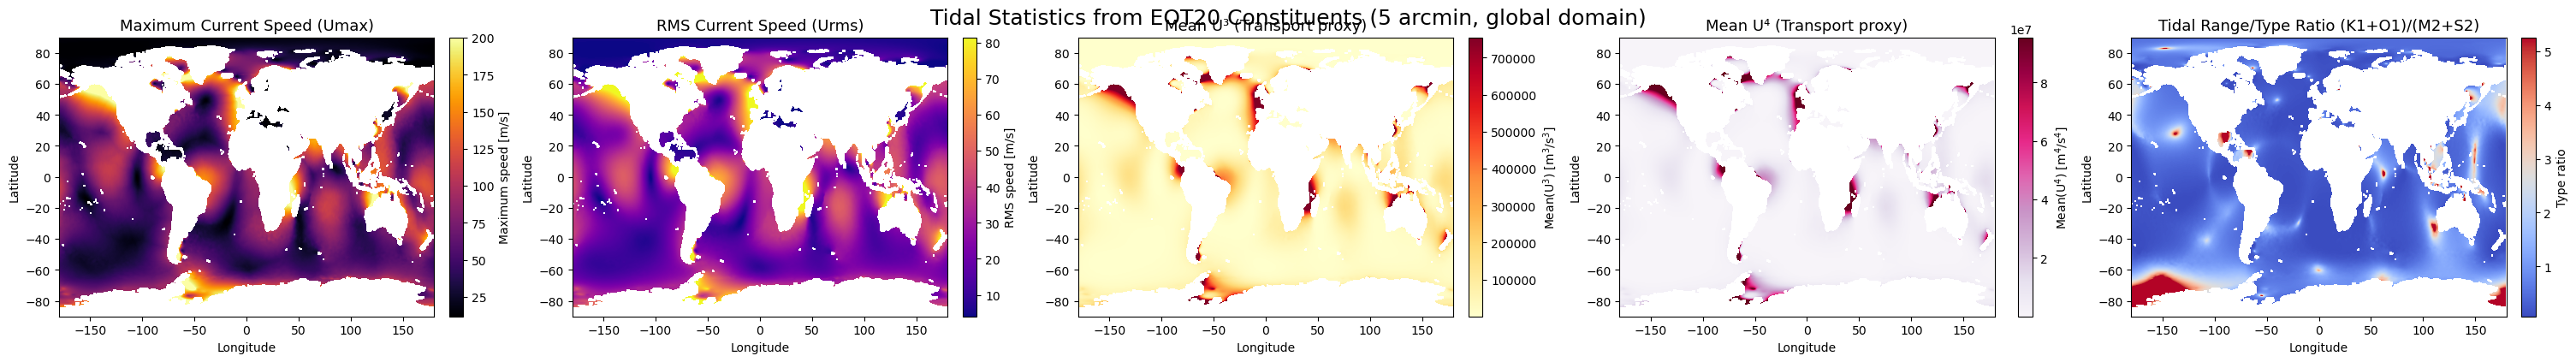

In [16]:

# ---- SAVE tidal statistic maps as netcdf files ----
# Export as xarray DataArrays, then save as NetCDF
stat_saves = {
    "umax": (Umax, "Maximum current speed [m/s]"),
    "urms": (Urms, "RMS current speed [m/s]"),
    "u3":   (U3, "Mean(U^3) [m^3/s^3]"),
    "u4":   (U4, "Mean(U^4) [m^4/s^4]"),
    "tidal_ratio": (ratio_diurnal_semidiurnal, "Tidal range/type ratio (K1+O1)/(M2+S2)"),
}
save_dir = DATA_DIR / "derived_eot20_stats"
save_dir.mkdir(exist_ok=True)
lat_da = xr.DataArray(lats_5arcmin, dims="lat", name="lat", attrs={"units": "degrees_north"})
lon_da = xr.DataArray(lons_5arcmin, dims="lon", name="lon", attrs={"units": "degrees_east"})

for key, (array, long_name) in stat_saves.items():
    da = xr.DataArray(
        array,
        dims=("lat", "lon"),
        coords={"lat": lat_da, "lon": lon_da},
        name=key,
        attrs={"long_name": long_name}
    )
    nc_path = save_dir / f"EOT20_{key}_5arcmin.nc"
    print(f"Saving {key} to {nc_path}")
    da.to_netcdf(nc_path)

# --- Plotting: Panel for each statistic with colorbars ---
stat_names = [
    ("Maximum Current Speed (Umax)", Umax, "Maximum speed [m/s]", "inferno"),
    ("RMS Current Speed (Urms)", Urms, "RMS speed [m/s]", "plasma"),
    ("Mean U³ (Transport proxy)", U3, "Mean(U$^3$) [m$^3$/s$^3$]", "YlOrRd"),
    ("Mean U⁴ (Transport proxy)", U4, "Mean(U$^4$) [m$^4$/s$^4$]", "PuRd"),
    ("Tidal Range/Type Ratio (K1+O1)/(M2+S2)", ratio_diurnal_semidiurnal, "Type ratio", "coolwarm"),
]
fig, axes = plt.subplots(1, len(stat_names), figsize=(6*len(stat_names), 4), constrained_layout=True)

for i, (title, data, cbarlabel, cmap) in enumerate(stat_names):
    ax = axes[i]
    vmin = np.nanpercentile(data, 2) if "ratio" not in title else None
    vmax = np.nanpercentile(data, 98) if "ratio" not in title else None
    img = ax.imshow(
        data, extent=[-180, 180, -90, 90], origin='lower', aspect='auto',
        cmap=cmap, vmin=vmin, vmax=vmax
    )
    fig.colorbar(img, ax=ax, orientation="vertical", fraction=0.04, pad=0.04, label=cbarlabel)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)

plt.suptitle("Tidal Statistics from EOT20 Constituents (5 arcmin, global domain)", fontsize=18, y=1.02)
plt.show()


/tmp/ipykernel_2768351/2449978588.py:24: RuntimeWarning: Mean of empty slice
  function=lambda values: np.nanmean(values),


Saving umax (interpolated) to /gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_umax_5arcmin_interp_land.nc
Saving urms (interpolated) to /gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_urms_5arcmin_interp_land.nc
Saving u3 (interpolated) to /gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_u3_5arcmin_interp_land.nc
Saving u4 (interpolated) to /gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_u4_5arcmin_interp_land.nc
Saving tidal_ratio (interpolated) to /gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_tidal_ratio_5arcmin_interp_land.nc


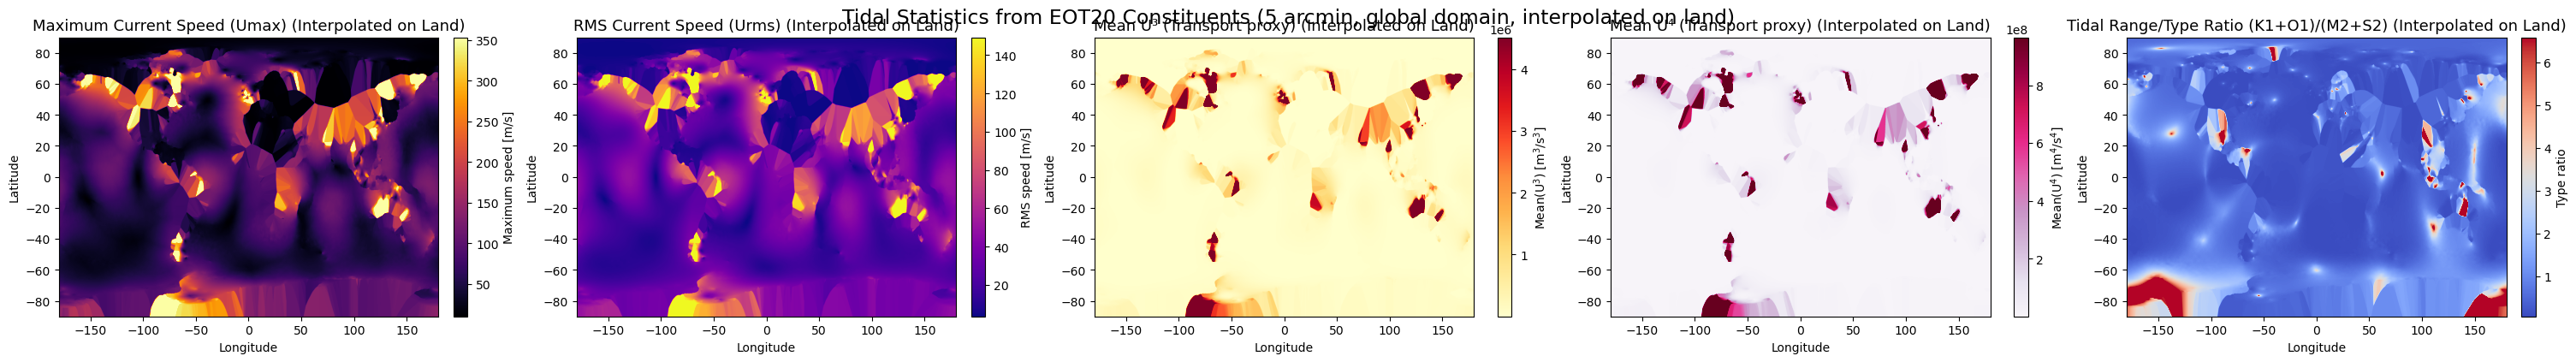

In [21]:
# ---- Interpolate tidal statistic maps onto land and plot them ----

import scipy.ndimage

# Export as xarray DataArrays, then save as NetCDF
stat_saves = {
    "umax": (Umax, "Maximum current speed [m/s]"),
    "urms": (Urms, "RMS current speed [m/s]"),
    "u3":   (U3, "Mean(U^3) [m^3/s^3]"),
    "u4":   (U4, "Mean(U^4) [m^4/s^4]"),
    "tidal_ratio": (ratio_diurnal_semidiurnal, "Tidal range/type ratio (K1+O1)/(M2+S2)"),
}
save_dir = DATA_DIR / "derived_eot20_stats"
save_dir.mkdir(exist_ok=True)
lat_da = xr.DataArray(lats_5arcmin, dims="lat", name="lat", attrs={"units": "degrees_north"})
lon_da = xr.DataArray(lons_5arcmin, dims="lon", name="lon", attrs={"units": "degrees_east"})

interpolated_stats = {}

for key, (array, long_name) in stat_saves.items():
    # Interpolate NaNs (on land) with nearest-neighbor method
    arr_interpolated = scipy.ndimage.generic_filter(
        array,
        function=lambda values: np.nanmean(values),
        size=5,
        mode='nearest'
    )
    # If still NaNs after filtering, do nearest for those pixels
    nan_mask = np.isnan(array)
    if np.any(nan_mask):
        # Use nearest valid data point for NaNs
        arr_tmp = array.copy()
        # Where nan, replace temporarily with large negative. Mask will ignore.
        arr_tmp[nan_mask] = np.nan
        # Binary mask: valid=1, nan=0
        mask_valid = (~nan_mask).astype(float)
        # Use distance transform to find index of nearest valid for each nan location
        from scipy.ndimage import distance_transform_edt
        # Indices of nearest valid
        idx = np.array(np.where(mask_valid)).T
        dist, inds = distance_transform_edt(nan_mask, return_indices=True)
        arr_nn = array[tuple(inds)]
        arr_interpolated[nan_mask] = arr_nn[nan_mask]
    interpolated_stats[key] = arr_interpolated

    # Save to NetCDF with interpolated data
    da = xr.DataArray(
        arr_interpolated,
        dims=("lat", "lon"),
        coords={"lat": lat_da, "lon": lon_da},
        name="data",
        attrs={"long_name": long_name + " (land interpolated)"}
    )
    nc_path = save_dir / f"EOT20_{key}_5arcmin_interp_land.nc"
    print(f"Saving {key} (interpolated) to {nc_path}")
    da.to_netcdf(nc_path)

# --- Plotting: Panel for each interpolated statistic with colorbars ---
stat_names_interp = [
    ("Maximum Current Speed (Umax)", interpolated_stats["umax"], "Maximum speed [m/s]", "inferno"),
    ("RMS Current Speed (Urms)", interpolated_stats["urms"], "RMS speed [m/s]", "plasma"),
    ("Mean U³ (Transport proxy)", interpolated_stats["u3"], "Mean(U$^3$) [m$^3$/s$^3$]", "YlOrRd"),
    ("Mean U⁴ (Transport proxy)", interpolated_stats["u4"], "Mean(U$^4$) [m$^4$/s$^4$]", "PuRd"),
    ("Tidal Range/Type Ratio (K1+O1)/(M2+S2)", interpolated_stats["tidal_ratio"], "Type ratio", "coolwarm"),
]

fig, axes = plt.subplots(1, len(stat_names_interp), figsize=(6*len(stat_names_interp), 4), constrained_layout=True)

for i, (title, data, cbarlabel, cmap) in enumerate(stat_names_interp):
    ax = axes[i]
    vmin = np.nanpercentile(data, 2) if "ratio" not in title else None
    vmax = np.nanpercentile(data, 98) if "ratio" not in title else None
    img = ax.imshow(
        data, extent=[-180, 180, -90, 90], origin='lower', aspect='auto',
        cmap=cmap, vmin=vmin, vmax=vmax
    )
    fig.colorbar(img, ax=ax, orientation="vertical", fraction=0.04, pad=0.04, label=cbarlabel)
    ax.set_title(title + " (Interpolated on Land)", fontsize=13)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)

plt.suptitle("Tidal Statistics from EOT20 Constituents (5 arcmin, global domain, interpolated on land)", fontsize=17, y=1.02)
plt.show()


<xarray.Dataset> Size: 133MB
Dimensions:    (lat: 1441, lon: 2881)
Coordinates:
  * lat        (lat) float64 12kB -90.0 -89.88 -89.75 ... 89.75 89.88 90.0
  * lon        (lon) float64 23kB 0.0 0.125 0.25 0.375 ... 359.8 359.9 360.0
Data variables:
    amplitude  (lat, lon) float64 33MB ...
    phase      (lat, lon) float64 33MB ...
    imag       (lat, lon) float64 33MB ...
    real       (lat, lon) float64 33MB ...
Attributes: (12/13)
    title:                      DGFI-TUM global empirical ocean tide model EO...
    license:                    None
    history:                    2021-06-25
    project:                    EOT20
    product_version:            1.0.0
    summary:                    EOT20 global ocean tide solution computed fro...
    ...                         ...
    contact:                    michael.hart-davis@tum.de
    date_created:               2020-11-13
    geospatial_lat_resolution:  0.125
    geospatial_lon_resolution:  0.125
    Conventions:             

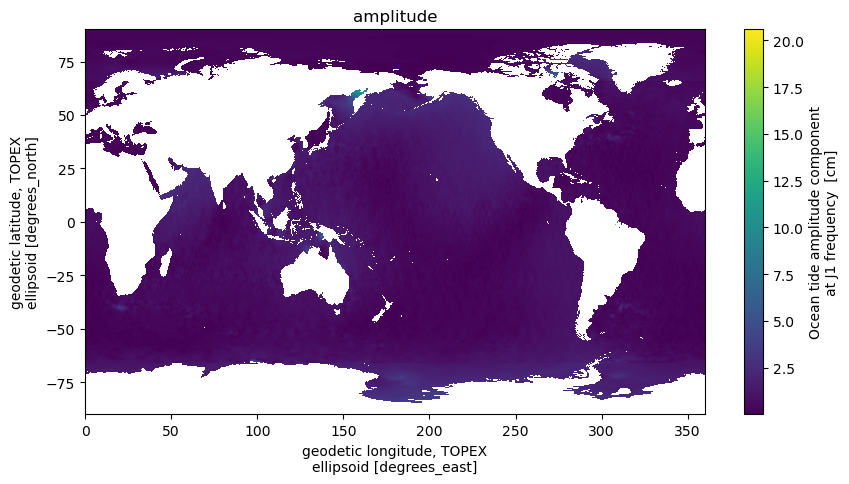

In [17]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

nc_path = "/gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/J1_ocean_eot20.nc"
ds = xr.open_dataset(nc_path)
print(ds)

# Try to find variables relating to amplitude, commonly named 'amplitude', 'amp', or 'h'
amp_var_candidates = [v for v in ds.data_vars if 'amp' in v.lower() or 'ampl' in v.lower() or v.lower()=='h']
if not amp_var_candidates:
    print("Could not find an obvious amplitude variable in dataset!")
else:
    for v in amp_var_candidates:
        print(f"Plotting amplitude variable: {v}")
        plt.figure(figsize=(10, 5))
        data = ds[v]
        # Usually amplitude dims: (lat, lon) or (y, x), possibly with 'constituent' dim
        if 'constituent' in data.dims:
            for idx in range(data.sizes['constituent']):
                plt.subplot(1, data.sizes['constituent'], idx + 1)
                cur_data = data.isel(constituent=idx)
                cur_data.plot()
                plt.title(f"{v} (constituent {idx})")
            plt.tight_layout()
        else:
            data.plot()
            plt.title(f"{v}")
        plt.show()

ds.close()


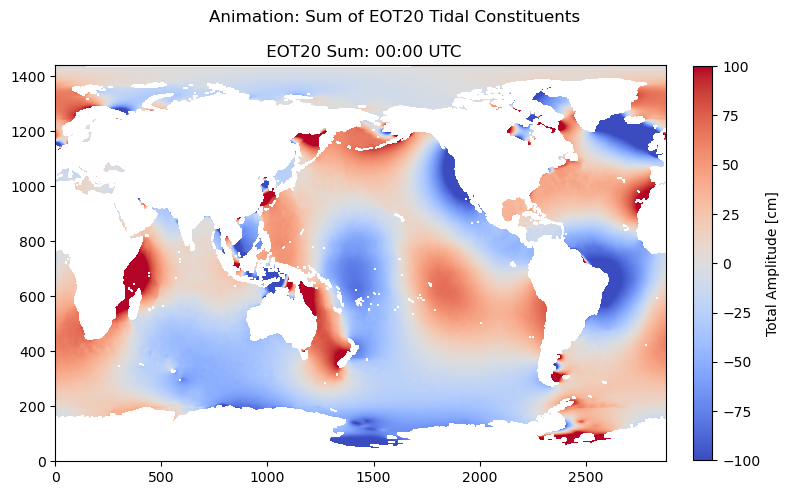

In [18]:
# --------------------------------------------------------------
# This cell computes the omega-weighted sum of EOT20 constituents (using amplitude and phase!)
# as a function of time and creates an animation showing the spatiotemporal evolution.
# (no masking with land mask; phases included).
# No EOT20_sum.nc file is written. Animation is generated in memory only.

# --- WHY IS THE ANIMATION REVERSED? ---
# In tidal equations, the standard time-dependent term is:
#   h(t) = amp * cos(omega*t + phase)
# However, many tidal models (including the EOT distribution and classic texts)
# define the phase as corresponding to *cos(omega*t - phase)*.
# If phase refers to the "time of maximum", then our convention should be:
#   h(t) = amp * cos(omega*t - phase)
# If you accidentally use "+" here (as in the original code),
# the result will be a time-reversed animation (i.e., the propagation will be backwards).
# => FIX: Change +phase to -phase in the cos() argument.

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import matplotlib.animation as animation
from pathlib import Path

# Data directory (same as @file_context_0):
DATA_DIR = Path("/gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides")

TIDAL_CONSTITUENTS = [
    "J1", "K1", "K2", "M2", "M4", "MF", "MM", "N2", "O1", "P1",
    "Q1", "S1", "S2", "2N2", "T2", "SA", "SSA"
]
OMEGA_RAD = {
    "J1": 0.976506, "K1": 1.0027379, "K2": 2.0054758, "M2": 0.932273,
    "M4": 1.864546, "MF": 1.0980331, "MM": 0.053234, "N2": 0.895982,
    "O1": 0.929536, "P1": 0.997262, "Q1": 0.893244, "S1": 1.0,
    "S2": 2.0, "2N2": 0.897164, "T2": 2.0, "SA": 0.0, "SSA": 0.0
}

# Collect shape for grid, using the first available amplitude field:
nc_files = sorted(DATA_DIR.glob("*_ocean_eot20.nc"))
shape_from_coords = None
for f in nc_files:
    with xr.open_dataset(f) as ds:
        if "amplitude" in ds.data_vars:
            shape_from_coords = ds["amplitude"].shape
        else:
            shape_from_coords = list(ds.data_vars.values())[0].shape
        break

# --- Compute total sum over constituents using amplitude and phase, over time for animation ---
# Animation parameters
n_frames = 60  # Number of frames in the animation
t_min = 0      # seconds
t_max = 2 * 24 * 3600   # animate over two days
times_seconds = np.linspace(t_min, t_max, n_frames)
if t_max <= 3*24*3600:
    time_labels = [f"{int(t//3600):02d}:{int((t%3600)//60):02d} UTC" for t in times_seconds]
else:
    time_labels = [f"{t/86400:.1f} days" for t in times_seconds]

# Pre-load amplitude and phase for all tidal constituents
amp_phase_constituents = {}
omega_secs = {}

for f in nc_files:
    possible_name = f.stem.split('_')[0]
    if possible_name not in TIDAL_CONSTITUENTS:
        print(f"Skipping unknown or non-tidal constituent: {possible_name}")
        continue
    name = possible_name
    omega = OMEGA_RAD[name]
    omega_sec = omega / 3600.0  # radians per second

    ds = xr.open_dataset(f)
    if "amplitude" in ds and "phase" in ds:
        amp = ds["amplitude"]
        phase = ds["phase"]
    else:
        # Try fallback variable names (rare)
        vars = list(ds.data_vars)
        amp = ds[vars[0]]
        phase = ds[vars[1]] if len(vars) > 1 else xr.zeros_like(amp)
    # Convert phase to radians if necessary
    phase_units = str(phase.attrs.get("units", "")).lower()
    if phase_units.startswith("deg"):
        phase_rad = np.deg2rad(phase)
    else:
        phase_rad = phase
    amp_phase_constituents[name] = (amp, phase_rad)
    omega_secs[name] = omega_sec
    ds.close()

# --- Compute h_total at each time frame (NOTE: use minus sign for phase!) ---
h_total_frames = []
for t in times_seconds:
    h_total = None
    for name in amp_phase_constituents:
        amp, phase = amp_phase_constituents[name]
        amp_at_t = amp * np.cos(omega_secs[name] * t - phase)  # <--- CHANGED "+" to "-"
        if h_total is None:
            h_total = amp_at_t
        else:
            h_total = h_total + amp_at_t
    # Convert to np.array for animation (strips coords)
    h_total_frames.append(np.array(h_total))

# --- Animation of h_total ---
fig, ax = plt.subplots(figsize=(8, 5))
# Get color scale limits, or use static values
vabs = np.nanmax([np.nanmax(np.abs(frame)) for frame in h_total_frames])
vmin = -100#-vabs if vabs > 0 else -100
vmax = 100#vabs if vabs > 0 else 100

im = ax.imshow(h_total_frames[0], origin='lower', aspect='auto', cmap='coolwarm', vmin=vmin, vmax=vmax)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.04)
cbar.set_label("Total Amplitude [cm]")

title = ax.set_title(f" EOT20 Sum: {time_labels[0]}")

def update(frame_idx):
    im.set_data(h_total_frames[frame_idx])
    title.set_text(f"Omega-weighted EOT20 Sum: {time_labels[frame_idx]}")
    return [im, title]

ani = animation.FuncAnimation(fig, update, frames=len(h_total_frames), interval=100, blit=False)

plt.suptitle("Animation: Sum of EOT20 Tidal Constituents")
plt.tight_layout()
plt.show()

# Optionally save animation as MP4
mp4_filename = "eot20_total_sum_animation_temp.mp4"
ani.save(mp4_filename, writer='ffmpeg', dpi=180)



<xarray.Dataset> Size: 133MB
Dimensions:    (lat: 1441, lon: 2881)
Coordinates:
  * lat        (lat) float64 12kB -90.0 -89.88 -89.75 ... 89.75 89.88 90.0
  * lon        (lon) float64 23kB 0.0 0.125 0.25 0.375 ... 359.8 359.9 360.0
Data variables:
    amplitude  (lat, lon) float64 33MB ...
    phase      (lat, lon) float64 33MB ...
    imag       (lat, lon) float64 33MB ...
    real       (lat, lon) float64 33MB ...
Attributes: (12/13)
    title:                      DGFI-TUM global empirical ocean tide model EO...
    license:                    None
    history:                    2021-06-25
    project:                    EOT20
    product_version:            1.0.0
    summary:                    EOT20 global ocean tide solution computed fro...
    ...                         ...
    contact:                    michael.hart-davis@tum.de
    date_created:               2020-11-13
    geospatial_lat_resolution:  0.125
    geospatial_lon_resolution:  0.125
    Conventions:             

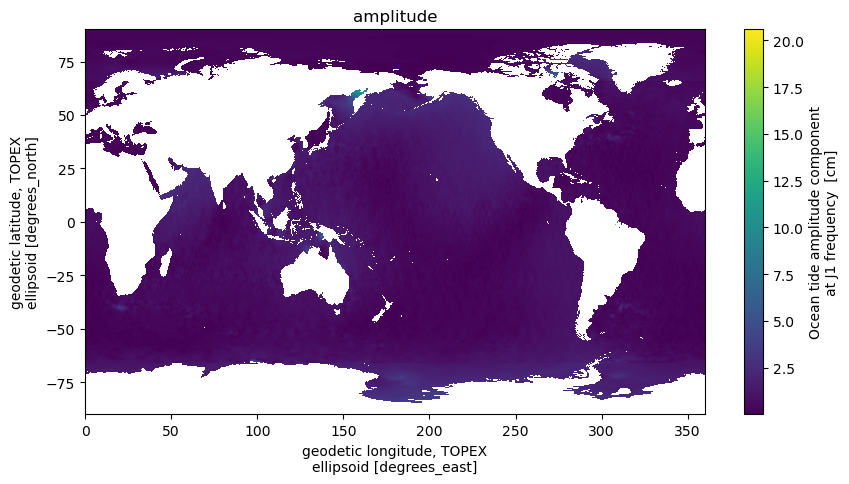

In [47]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

nc_path = "/gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/J1_ocean_eot20.nc"
ds = xr.open_dataset(nc_path)
print(ds)

# Try to find variables relating to amplitude, commonly named 'amplitude', 'amp', or 'h'
amp_var_candidates = [v for v in ds.data_vars if 'amp' in v.lower() or 'ampl' in v.lower() or v.lower()=='h']
if not amp_var_candidates:
    print("Could not find an obvious amplitude variable in dataset!")
else:
    for v in amp_var_candidates:
        print(f"Plotting amplitude variable: {v}")
        plt.figure(figsize=(10, 5))
        data = ds[v]
        # Usually amplitude dims: (lat, lon) or (y, x), possibly with 'constituent' dim
        if 'constituent' in data.dims:
            for idx in range(data.sizes['constituent']):
                plt.subplot(1, data.sizes['constituent'], idx + 1)
                cur_data = data.isel(constituent=idx)
                cur_data.plot()
                plt.title(f"{v} (constituent {idx})")
            plt.tight_layout()
        else:
            data.plot()
            plt.title(f"{v}")
        plt.show()

ds.close()


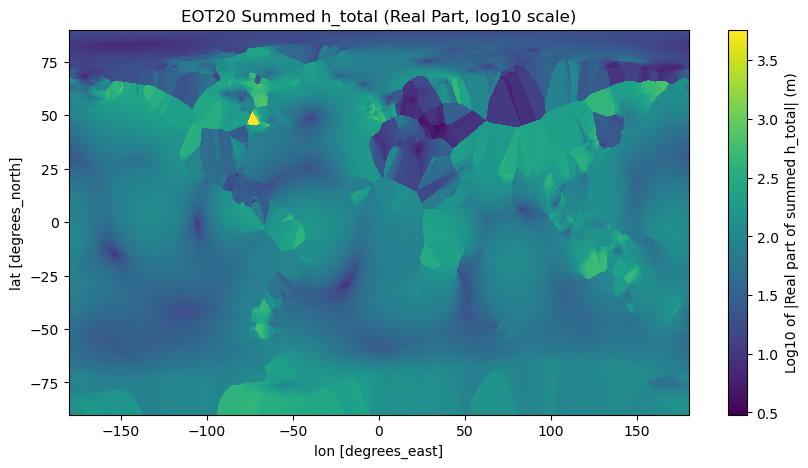

In [3]:
import xarray as xr
import matplotlib.pyplot as plt

nc_file = "../../data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/EOT20_umax_5arcmin_interp_land.nc"
ds = xr.open_dataset(nc_file)

# Plot real part
plt.figure(figsize=(10, 5))
import numpy as np

# Take absolute value before log, avoid log(0) by adding a small constant
data = np.abs(ds['data']) + 1e-10
log_data = np.log10(data)

log_data_plot = log_data.plot(
    cbar_kwargs={'label': 'Log10 of |Real part of summed h_total| (m)'}
)
plt.title("EOT20 Summed h_total (Real Part, log10 scale)")
plt.show()


ds.close()

In [4]:
ds

<xarray.Dataset> Size: 37MB
Dimensions:  (lat: 2160, lon: 4320)
Coordinates:
  * lat      (lat) float64 17kB -90.0 -89.92 -89.83 -89.75 ... 89.83 89.92 90.0
  * lon      (lon) float64 35kB -180.0 -179.9 -179.8 ... 179.8 179.9 180.0
Data variables:
    data     (lat, lon) float32 37MB 141.7 141.7 141.7 ... 16.63 16.63 16.63